# Lab 1.4 · Transformer blocks

**15–20 minutes · CPU · Python standard library**

## How to work through this notebook

Read the worked example, run the setup, then complete the exercises in order. Replace each `return None` placeholder with your code and run the cell below to check your result. Use the wrap-up to explain the output in your own words.

## Concepts and worked example

A decoder block has two different jobs. Its attention branch lets earlier positions influence the current one. Its feed-forward branch transforms features within each position. Both branches return the same shape as their input so the block can add their outputs back to the hidden state. These additions are called **residual connections**.

In a pre-normalized block, the branch sees normalized features while the residual path carries the incoming features directly. For example, if a row is `[3, 1]` and the branch returns `[-1, 2]`, the updated row is `[2, 3]`. The second branch reads this updated row after normalization. In the notebook, normalization is RMS-based and applied independently to each row. It divides features by their root mean square with a small epsilon for numerical stability.

The notebook supplies prefix averaging as a stand-in for causal attention and a tiny ReLU feature transform as the feed-forward branch. Turning branches off lets you separate cross-position mixing from within-position transformations. Lab 1.5 replaces the averaging idea with explicit attention scores.

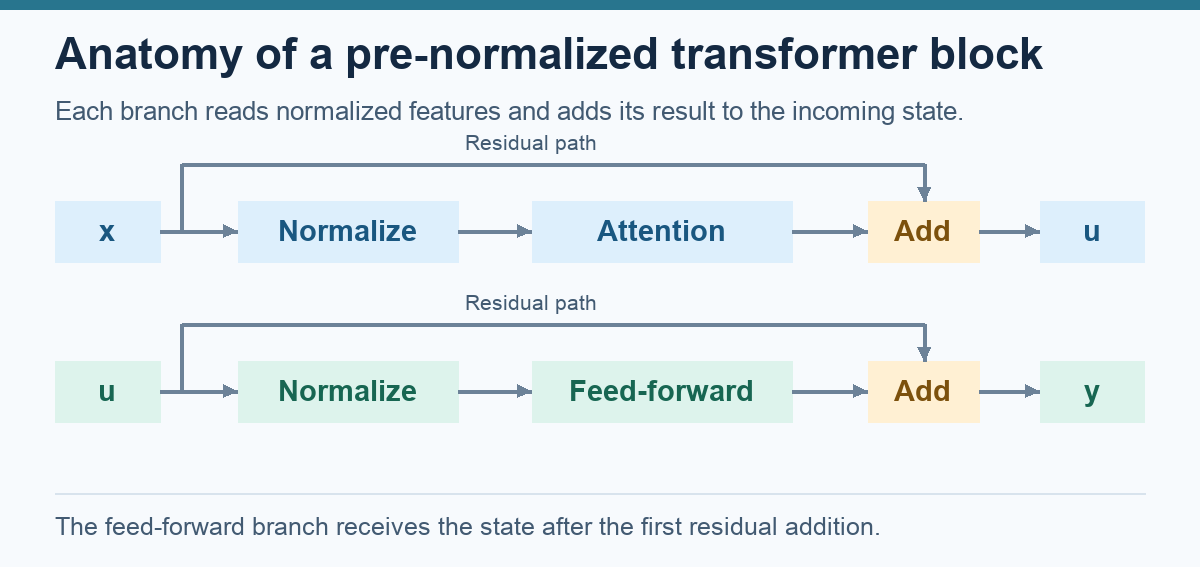

## Exercise map

1. **Wire a residual update** — Implement elementwise addition for two matrices of identical shape, then use it for the mixing branch.
2. **Assemble and ablate** — Run both updates in order and compare with runs that disable one branch at a time.

[Open the lab guide](README.md) for the exercise checklist.

In [ ]:
from math import sqrt

def normalize(row):
    rms = sqrt(sum(x * x for x in row) / len(row) + 1e-8)
    return [x / rms for x in row]

def mix_prefix(rows):
    return [[sum(row[j] for row in rows[:i + 1]) / (i + 1)
             for j in range(len(rows[i]))] for i in range(len(rows))]

def feed_forward(rows):
    return [[max(0, x - y), max(0, y - x)] for x, y in rows]

inputs = [[1.0, 0.0], [0.0, 2.0], [-1.0, 1.0]]

## Exercise 1. Wire a residual update

Implement elementwise addition of two equal-shaped lists of rows, then use it to add the supplied mixing branch to the input.

**Implementation hint** — Pair corresponding rows, then pair corresponding values inside each row.

**After running the check** — Each feature receives its own update and the output has the same sequence length and hidden width.

In [ ]:
def add_rows(left, right):
    return None

In [ ]:
mixed = mix_prefix([normalize(row) for row in inputs])
after_attention = add_rows(inputs, mixed)
if after_attention is not None:
    assert add_rows([[1, 2], [3, 4]], [[-1, 1], [1, -4]]) == [[0, 3], [4, 0]]
    assert all(len(row) == 2 for row in after_attention)
    print("PASS — first residual update:", after_attention)

## Exercise 2. Assemble and ablate

Complete the pipeline. Start with the input. If enabled, normalize it, mix prefixes, and add the residual. If the feed-forward branch is enabled, normalize the resulting state, apply that branch, and add its residual.

**Implementation hint** — Keep a variable for the current state. The FFN receives the normalized state after any attention update, while its residual uses that same state before normalization.

**After running the check** — Change an early input and inspect later rows. Without the mixing branch, an earlier row cannot change a later row.

In [ ]:
def block(rows, use_attention=True, use_feed_forward=True):
    return None

In [ ]:
check_passed = False
full = block(inputs)
if full is not None:
    only_attention = block(inputs, use_feed_forward=False)
    only_ffn = block(inputs, use_attention=False)
    assert block(inputs, False, False) == inputs
    assert only_attention == after_attention
    assert full == add_rows(only_attention, feed_forward([normalize(row) for row in only_attention]))
    changed = [[2.0, 1.0], *inputs[1:]]
    assert block(changed, use_attention=False)[1:] == only_ffn[1:]
    assert block(changed, use_feed_forward=False)[1:] != only_attention[1:]
    print("Input          Attention only        FFN only             Full")
    for row in zip(inputs, only_attention, only_ffn, full):
        print("  ".join(str([round(x, 3) for x in state]) for state in row))
    print("PASS — only the mixing branch carries earlier input changes forward")
    check_passed = True
if not check_passed:
    print("Complete add_rows and block and rerun the checks in order.")

## Optional extension · Hidden width and feed-forward weights

The book separates the embedding, repeated blocks, and vocabulary head. Within a block it distinguishes attention, normalization, and the feed-forward network. The toy feed-forward function stands in for a position-wise network. In a simple two-projection version, the intermediate width can be larger than the residual width.

Count the weights for the expansion and contraction of a width-4 feed-forward branch with intermediate widths 8 and 16. Explain why the output can still be added to a width-4 residual.

**Reading** · Philip Kiely, *Inference Engineering*, §2.2.2, pp. 50–51.

In [ ]:
hidden = 4
for intermediate in (8, 16):
    expand = (hidden, intermediate)
    contract = (intermediate, hidden)
    count = 2 * hidden * intermediate
    assert contract[1] == hidden
    print("Projections:", expand, contract, "weights without biases:", count)

## Wrap-up

Change the last input row. Which earlier rows can change? Where would you look if a feature changes even with the mixing branch disabled?

## Optional system exercise · Isolating a bad block output

Pick one position where the full block and the attention-only run differ. Trace the normalized row and the feed-forward update. Explain where you would insert a shape check or comparison if a fused implementation disagreed with the reference.